In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/daikhiyassine/dataset/corrosion/jacques-barbary-AFH3sddcN9E-unsplash_jpg.rf.fd3b734a6d2d3a160e256ce2ae5395ad.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/0987_JPG_jpg.rf.9e6e49fda18d48f5c05b00cf2d6c1808.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/Harsha-655-_jpg.rf.3442e83858fd2e05bc255b5d39bd0764.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/Fotos-buenas-29-_jpg.rf.3fe215cbe2a1b64a3ced46b3808a62d1.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/GEN_223_jpg.rf.00345cd442f4b3efbf23aca438c8f6e3.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/247-_jpeg.rf.0b922fbf79c56631f4e7bd018bf7f94f.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/240_F_121815341_fgkcOC3UzE6KDIMZGzx9TCEvz1vXxJQT_jpg.rf.83dfc29557b919202cf5a5ec19ae0b27.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/img49_jpg.rf.097401258acade33cf0d57d8d3845645.jpg
/kaggle/input/datasets/daikhiyassine/dataset/corrosion/0903_JPG_

In [2]:
import os

DATASET_PATH = "/kaggle/input/datasets/daikhiyassine/dataset"

# Vérifier le contenu de train/val/test
for split in ["train", "val", "test"]:
    split_path = os.path.join(DATASET_PATH, split)
    print(f"\n📁 {split}/")
    if os.path.isdir(split_path):
        for item in os.listdir(split_path):
            item_path = os.path.join(split_path, item)
            if os.path.isdir(item_path):
                n = len(os.listdir(item_path))
                print(f"   {item}/  →  {n} fichiers")

# Vérifier le contenu des dossiers "classe" au niveau racine
print("\n📁 Dossiers classes au niveau racine du dataset/")
for cls in ["corrosion", "spalling", "normal", "cracks"]:
    cls_path = os.path.join(DATASET_PATH, cls)
    if os.path.isdir(cls_path):
        n = len(os.listdir(cls_path))
        print(f"   {cls}/  →  {n} fichiers")


📁 train/
   corrosion/  →  3936 fichiers
   spalling/  →  3747 fichiers
   normal/  →  3594 fichiers
   cracks/  →  3430 fichiers

📁 val/
   corrosion/  →  844 fichiers
   spalling/  →  803 fichiers
   normal/  →  770 fichiers
   cracks/  →  735 fichiers

📁 test/
   corrosion/  →  844 fichiers
   spalling/  →  804 fichiers
   normal/  →  771 fichiers
   cracks/  →  735 fichiers

📁 Dossiers classes au niveau racine du dataset/
   corrosion/  →  5624 fichiers
   spalling/  →  5354 fichiers
   normal/  →  5135 fichiers
   cracks/  →  4900 fichiers


Résumé :

TRAIN (total: 14707)
   corrosion: 3936
   spalling: 3747
   normal: 3594
   cracks: 3430

VAL (total: 3152)
   corrosion: 844
   spalling: 803
   normal: 770
   cracks: 735

TEST (total: 3154)
   corrosion: 844
   spalling: 804
   normal: 771
   cracks: 735


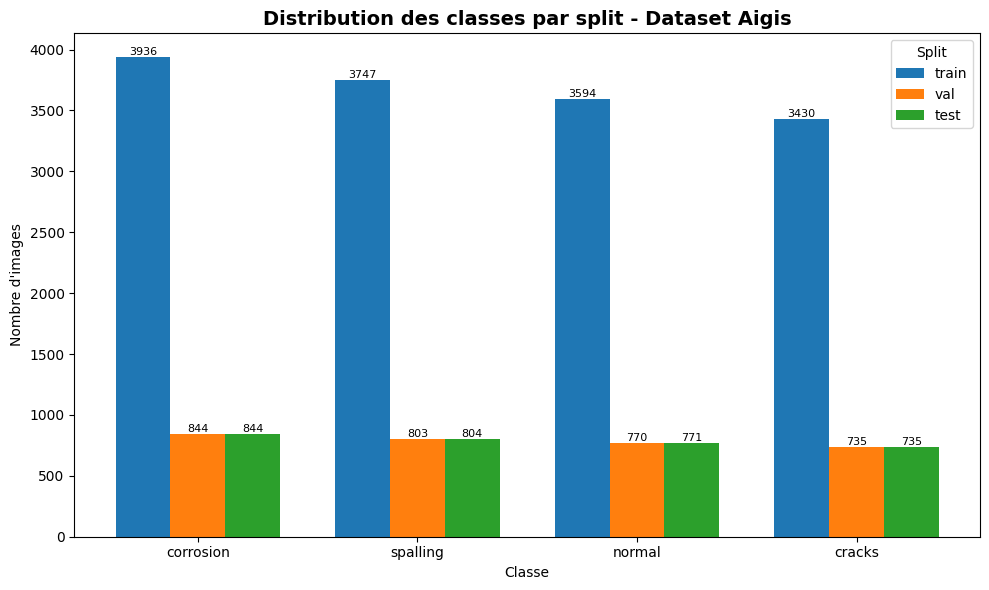


Ratio des classes dans train (équilibre) :
   corrosion: 26.8%
   spalling: 25.5%
   normal: 24.4%
   cracks: 23.3%


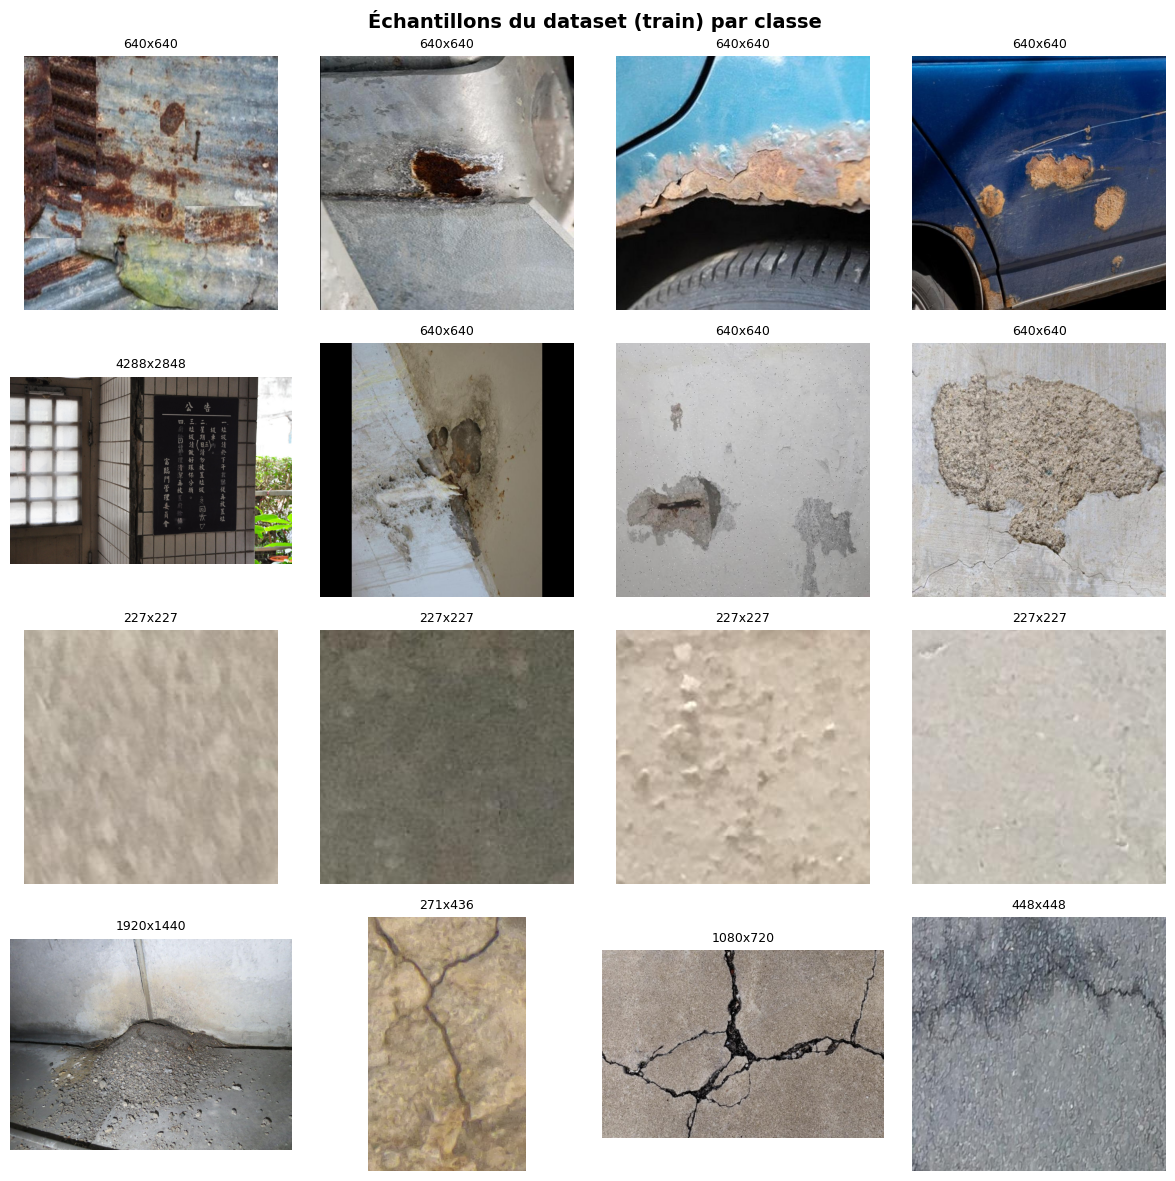


Analyse des dimensions (échantillon de 100 images de train) :
   Largeur - min: 227, max: 3888, moyenne: 707
   Hauteur - min: 54, max: 4032, moyenne: 664


In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import random

DATASET_PATH = "/kaggle/input/datasets/daikhiyassine/dataset"
SPLITS = ["train", "val", "test"]
CLASSES = ["corrosion", "spalling", "normal", "cracks"]

# 1️⃣ Comptage complet par split et par classe
counts = {split: {} for split in SPLITS}
for split in SPLITS:
    for cls in CLASSES:
        cls_path = os.path.join(DATASET_PATH, split, cls)
        counts[split][cls] = len(os.listdir(cls_path)) if os.path.isdir(cls_path) else 0

print("Résumé :")
for split in SPLITS:
    total = sum(counts[split].values())
    print(f"\n{split.upper()} (total: {total})")
    for cls in CLASSES:
        print(f"   {cls}: {counts[split][cls]}")

# 2️⃣ Graphique en barres groupées (train/val/test côte à côte par classe)
x = np.arange(len(CLASSES))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 6))

for i, split in enumerate(SPLITS):
    values = [counts[split][cls] for cls in CLASSES]
    bars = ax.bar(x + i * width, values, width, label=split)
    ax.bar_label(bars, fontsize=8)

ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'images")
ax.set_title("Distribution des classes par split - Dataset Aigis", fontsize=14, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(CLASSES)
ax.legend(title="Split")
plt.tight_layout()
plt.show()

# 3️⃣ Vérification de l'équilibre des classes (ratio train)
print("\nRatio des classes dans train (équilibre) :")
total_train = sum(counts["train"].values())
for cls in CLASSES:
    pct = counts["train"][cls] / total_train * 100
    print(f"   {cls}: {pct:.1f}%")

# 4️⃣ Échantillons visuels (depuis train uniquement)
n_samples = 4
fig, axes = plt.subplots(len(CLASSES), n_samples, figsize=(n_samples * 3, len(CLASSES) * 3))

for i, cls in enumerate(CLASSES):
    cls_path = os.path.join(DATASET_PATH, "train", cls)
    images = os.listdir(cls_path)
    sample_imgs = random.sample(images, min(n_samples, len(images)))
    
    for j, img_name in enumerate(sample_imgs):
        img = Image.open(os.path.join(cls_path, img_name))
        ax = axes[i, j]
        ax.imshow(img)
        ax.axis('off')
        if j == 0:
            ax.set_ylabel(cls, fontsize=12, fontweight='bold', rotation=90)
        ax.set_title(f"{img.size[0]}x{img.size[1]}", fontsize=9)

plt.suptitle("Échantillons du dataset (train) par classe", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5️⃣ Analyse des dimensions d'images (train, échantillon aléatoire)
print("\nAnalyse des dimensions (échantillon de 100 images de train) :")
all_train_images = []
for cls in CLASSES:
    cls_path = os.path.join(DATASET_PATH, "train", cls)
    for img_name in os.listdir(cls_path):
        all_train_images.append(os.path.join(cls_path, img_name))

sample = random.sample(all_train_images, min(100, len(all_train_images)))
sizes = [Image.open(p).size for p in sample]
widths, heights = zip(*sizes)
print(f"   Largeur - min: {min(widths)}, max: {max(widths)}, moyenne: {np.mean(widths):.0f}")
print(f"   Hauteur - min: {min(heights)}, max: {max(heights)}, moyenne: {np.mean(heights):.0f}")

In [4]:
plt.savefig('/kaggle/working/distribution_classes.png', dpi=150, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

In [5]:
plt.savefig('/kaggle/working/echantillons_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

In [6]:
import json

resultats = {
    "counts": counts,
    "total_par_split": {split: sum(counts[split].values()) for split in SPLITS},
    "ratio_classes_train": {cls: counts["train"][cls] / sum(counts["train"].values()) * 100 for cls in CLASSES},
    "dimensions": {
        "largeur_min": min(widths), "largeur_max": max(widths), "largeur_moy": float(np.mean(widths)),
        "hauteur_min": min(heights), "hauteur_max": max(heights), "hauteur_moy": float(np.mean(heights))
    }
}

with open('/kaggle/working/resultats_visualisation.json', 'w') as f:
    json.dump(resultats, f, indent=2, ensure_ascii=False)

print("Résultats sauvegardés dans /kaggle/working/resultats_visualisation.json")

Résultats sauvegardés dans /kaggle/working/resultats_visualisation.json


In [7]:
import os
import hashlib
from PIL import Image, ImageFile
import numpy as np
from collections import defaultdict
import json

ImageFile.LOAD_TRUNCATED_IMAGES = True  # évite certains crashs sur images tronquées

DATASET_PATH = "/kaggle/input/datasets/daikhiyassine/dataset"
SPLITS = ["train", "val", "test"]
CLASSES = ["corrosion", "spalling", "normal", "cracks"]
EFFICIENTNETB2_INPUT_SIZE = 260  # taille native d'EfficientNetB2

# ============================================================
# 1️⃣ Détection des images corrompues / illisibles
# ============================================================
print("=" * 60)
print("1. VÉRIFICATION DES IMAGES CORROMPUES")
print("=" * 60)

corrupted_files = []

for split in SPLITS:
    for cls in CLASSES:
        cls_path = os.path.join(DATASET_PATH, split, cls)
        if not os.path.isdir(cls_path):
            continue
        for img_name in os.listdir(cls_path):
            img_path = os.path.join(cls_path, img_name)
            try:
                with Image.open(img_path) as img:
                    img.verify()  # vérifie l'intégrité sans charger complètement
            except Exception as e:
                corrupted_files.append((img_path, str(e)))

print(f"\nImages corrompues trouvées : {len(corrupted_files)}")
for path, err in corrupted_files[:10]:
    print(f"   ❌ {path} → {err}")

# ============================================================
# 2️⃣ Détection des doublons (hash MD5 du contenu)
# ============================================================
print("\n" + "=" * 60)
print("2. DÉTECTION DES DOUBLONS (par hash MD5)")
print("=" * 60)

def get_file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

hash_map = defaultdict(list)

for split in SPLITS:
    for cls in CLASSES:
        cls_path = os.path.join(DATASET_PATH, split, cls)
        if not os.path.isdir(cls_path):
            continue
        for img_name in os.listdir(cls_path):
            img_path = os.path.join(cls_path, img_name)
            try:
                h = get_file_hash(img_path)
                hash_map[h].append(img_path)
            except Exception:
                continue

duplicates = {h: paths for h, paths in hash_map.items() if len(paths) > 1}
print(f"\nGroupes de doublons trouvés : {len(duplicates)}")
total_duplicate_files = sum(len(v) - 1 for v in duplicates.values())
print(f"Fichiers en trop (à supprimer si on garde 1 copie/groupe) : {total_duplicate_files}")

# Vérifier si des doublons existent ENTRE train/val/test (fuite de données = grave)
print("\n⚠️  Vérification des fuites train/val/test (doublons entre splits) :")
leak_count = 0
for h, paths in duplicates.items():
    splits_involved = set()
    for p in paths:
        for split in SPLITS:
            if f"/{split}/" in p:
                splits_involved.add(split)
    if len(splits_involved) > 1:
        leak_count += 1

print(f"   Groupes de doublons répartis sur plusieurs splits : {leak_count}")
if leak_count > 0:
    print("   🚨 ATTENTION : ceci fausse l'évaluation (data leakage train→val/test)")

# ============================================================
# 3️⃣ Analyse des tailles / ratios d'aspect (impact resize EfficientNetB2)
# ============================================================
print("\n" + "=" * 60)
print("3. ANALYSE DES DIMENSIONS (pour resize EfficientNetB2 260x260)")
print("=" * 60)

dimensions = []
aspect_ratios = []
modes = defaultdict(int)  # RGB, RGBA, L, CMYK...

sample_paths = []
for split in SPLITS:
    for cls in CLASSES:
        cls_path = os.path.join(DATASET_PATH, split, cls)
        if os.path.isdir(cls_path):
            for img_name in os.listdir(cls_path):
                sample_paths.append(os.path.join(cls_path, img_name))

# échantillon pour ne pas tout scanner (ajuste n si besoin)
import random
sample = random.sample(sample_paths, min(500, len(sample_paths)))

for path in sample:
    try:
        with Image.open(path) as img:
            w, h = img.size
            dimensions.append((w, h))
            aspect_ratios.append(w / h)
            modes[img.mode] += 1
    except Exception:
        continue

widths, heights = zip(*dimensions)
print(f"\nDimensions (échantillon n={len(dimensions)}) :")
print(f"   Largeur  - min: {min(widths)}, max: {max(widths)}, moyenne: {np.mean(widths):.0f}")
print(f"   Hauteur  - min: {min(heights)}, max: {max(heights)}, moyenne: {np.mean(heights):.0f}")
print(f"   Ratio d'aspect - min: {min(aspect_ratios):.2f}, max: {max(aspect_ratios):.2f}, moyenne: {np.mean(aspect_ratios):.2f}")
print(f"\nModes de couleur détectés : {dict(modes)}")

if any(m != "RGB" for m in modes):
    print("   ⚠️  Des images non-RGB détectées (grayscale/RGBA) → conversion RGB nécessaire avant EfficientNetB2")

extreme_ratio = [r for r in aspect_ratios if r < 0.5 or r > 2.0]
print(f"\nImages avec ratio d'aspect extrême (<0.5 ou >2.0) : {len(extreme_ratio)} → risque de déformation au resize {EFFICIENTNETB2_INPUT_SIZE}x{EFFICIENTNETB2_INPUT_SIZE}")

# ============================================================
# 4️⃣ Résumé + sauvegarde du rapport
# ============================================================
print("\n" + "=" * 60)
print("4. RÉSUMÉ")
print("=" * 60)

rapport = {
    "images_corrompues": len(corrupted_files),
    "fichiers_corrompus": [p for p, _ in corrupted_files],
    "groupes_doublons": len(duplicates),
    "fichiers_doublons_en_trop": total_duplicate_files,
    "fuites_entre_splits": leak_count,
    "dimensions": {
        "largeur_min": min(widths), "largeur_max": max(widths), "largeur_moy": float(np.mean(widths)),
        "hauteur_min": min(heights), "hauteur_max": max(heights), "hauteur_moy": float(np.mean(heights)),
        "ratio_aspect_moy": float(np.mean(aspect_ratios))
    },
    "modes_couleur": dict(modes),
    "images_ratio_extreme": len(extreme_ratio)
}

with open('/kaggle/working/rapport_data_cleaning.json', 'w') as f:
    json.dump(rapport, f, indent=2, ensure_ascii=False)

print("\n✅ Rapport sauvegardé dans /kaggle/working/rapport_data_cleaning.json")
print(f"\nÀ corriger avant entraînement EfficientNetB2 :")
print(f"   - Supprimer {len(corrupted_files)} image(s) corrompue(s)")
print(f"   - Dédupliquer {total_duplicate_files} fichier(s)")
if leak_count > 0:
    print(f"   - 🚨 URGENT : résoudre {leak_count} fuite(s) train/val/test")
if any(m != "RGB" for m in modes):
    print(f"   - Convertir les images non-RGB")

1. VÉRIFICATION DES IMAGES CORROMPUES

Images corrompues trouvées : 0

2. DÉTECTION DES DOUBLONS (par hash MD5)

Groupes de doublons trouvés : 3
Fichiers en trop (à supprimer si on garde 1 copie/groupe) : 3

⚠️  Vérification des fuites train/val/test (doublons entre splits) :
   Groupes de doublons répartis sur plusieurs splits : 3
   🚨 ATTENTION : ceci fausse l'évaluation (data leakage train→val/test)

3. ANALYSE DES DIMENSIONS (pour resize EfficientNetB2 260x260)

Dimensions (échantillon n=500) :
   Largeur  - min: 86, max: 4240, moyenne: 679
   Hauteur  - min: 73, max: 5438, moyenne: 621
   Ratio d'aspect - min: 0.14, max: 8.85, moyenne: 1.22

Modes de couleur détectés : {'RGB': 477, 'L': 23}
   ⚠️  Des images non-RGB détectées (grayscale/RGBA) → conversion RGB nécessaire avant EfficientNetB2

Images avec ratio d'aspect extrême (<0.5 ou >2.0) : 44 → risque de déformation au resize 260x260

4. RÉSUMÉ

✅ Rapport sauvegardé dans /kaggle/working/rapport_data_cleaning.json

À corriger av

In [8]:
import os
import shutil
import hashlib
from PIL import Image
import json

DATASET_PATH = "/kaggle/input/datasets/daikhiyassine/dataset"
CLEAN_PATH = "/kaggle/working/dataset_clean"
SPLITS = ["train", "val", "test"]
CLASSES = ["corrosion", "spalling", "normal", "cracks"]

# Ordre de priorité si un doublon existe entre splits : on garde train, on retire de val/test
SPLIT_PRIORITY = {"train": 0, "val": 1, "test": 2}

# ============================================================
# 1️⃣ Recalculer les hashs pour identifier précisément quoi retirer
# ============================================================
print("Étape 1/3 : identification des doublons à retirer...")

def get_file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

from collections import defaultdict
hash_map = defaultdict(list)

for split in SPLITS:
    for cls in CLASSES:
        cls_path = os.path.join(DATASET_PATH, split, cls)
        if not os.path.isdir(cls_path):
            continue
        for img_name in os.listdir(cls_path):
            img_path = os.path.join(cls_path, img_name)
            h = get_file_hash(img_path)
            hash_map[h].append((split, cls, img_name, img_path))

# Pour chaque groupe de doublons, on garde 1 seule copie (priorité train > val > test)
files_to_skip = set()  # chemins à NE PAS copier

for h, entries in hash_map.items():
    if len(entries) > 1:
        # trie par priorité de split, garde le premier, skip les autres
        entries_sorted = sorted(entries, key=lambda e: SPLIT_PRIORITY[e[0]])
        keep = entries_sorted[0]
        remove = entries_sorted[1:]
        for split, cls, img_name, img_path in remove:
            files_to_skip.add(img_path)
            print(f"   ❌ Retiré : {split}/{cls}/{img_name} (doublon de {keep[0]}/{keep[1]}/{keep[2]})")

print(f"\nTotal fichiers à exclure : {len(files_to_skip)}")

# ============================================================
# 2️⃣ Copier le dataset en excluant doublons + convertir non-RGB
# ============================================================
print("\nÉtape 2/3 : copie + conversion RGB...")

converted_count = 0
copied_count = 0

for split in SPLITS:
    for cls in CLASSES:
        src_dir = os.path.join(DATASET_PATH, split, cls)
        dst_dir = os.path.join(CLEAN_PATH, split, cls)
        os.makedirs(dst_dir, exist_ok=True)

        if not os.path.isdir(src_dir):
            continue

        for img_name in os.listdir(src_dir):
            src_path = os.path.join(src_dir, img_name)

            if src_path in files_to_skip:
                continue  # doublon exclu

            dst_path = os.path.join(dst_dir, img_name)

            try:
                with Image.open(src_path) as img:
                    if img.mode != "RGB":
                        img = img.convert("RGB")
                        converted_count += 1
                    img.save(dst_path)
                    copied_count += 1
            except Exception as e:
                print(f"   ⚠️ Erreur sur {src_path} : {e}")

print(f"\nImages copiées : {copied_count}")
print(f"Images converties en RGB : {converted_count}")

# ============================================================
# 3️⃣ Vérification finale
# ============================================================
print("\nÉtape 3/3 : vérification finale...")

final_counts = {}
for split in SPLITS:
    final_counts[split] = {}
    for cls in CLASSES:
        cls_path = os.path.join(CLEAN_PATH, split, cls)
        n = len(os.listdir(cls_path)) if os.path.isdir(cls_path) else 0
        final_counts[split][cls] = n

print("\nComptage final (dataset nettoyé) :")
for split in SPLITS:
    total = sum(final_counts[split].values())
    print(f"\n{split.upper()} (total: {total})")
    for cls in CLASSES:
        print(f"   {cls}: {final_counts[split][cls]}")

# Sauvegarde du rapport de nettoyage
rapport_clean = {
    "fichiers_exclus_doublons": list(files_to_skip),
    "images_converties_rgb": converted_count,
    "comptage_final": final_counts
}
with open('/kaggle/working/rapport_nettoyage_final.json', 'w') as f:
    json.dump(rapport_clean, f, indent=2, ensure_ascii=False)

print(f"\n✅ Dataset nettoyé disponible dans : {CLEAN_PATH}")
print("✅ Rapport sauvegardé dans /kaggle/working/rapport_nettoyage_final.json")

Étape 1/3 : identification des doublons à retirer...
   ❌ Retiré : test/spalling/427_yang_jpg.rf.642f33876b4e27774adef8e4bddd1afa.jpg (doublon de train/cracks/Image_-192-_jpg.rf.825feee6b7b43e6279e68bc3c6222db3.jpg)
   ❌ Retiré : val/spalling/train_train_0318.jpg (doublon de train/cracks/train_train_0318.jpg)
   ❌ Retiré : test/cracks/Image_-120-_jpg.rf.4ed26783423892fd1ef5ee730e985a50.jpg (doublon de val/spalling/262_yang_jpg.rf.2990160898519c5b450e727574fe50f5.jpg)

Total fichiers à exclure : 3

Étape 2/3 : copie + conversion RGB...

Images copiées : 21010
Images converties en RGB : 626

Étape 3/3 : vérification finale...

Comptage final (dataset nettoyé) :

TRAIN (total: 14707)
   corrosion: 3936
   spalling: 3747
   normal: 3594
   cracks: 3430

VAL (total: 3151)
   corrosion: 844
   spalling: 802
   normal: 770
   cracks: 735

TEST (total: 3152)
   corrosion: 844
   spalling: 803
   normal: 771
   cracks: 734

✅ Dataset nettoyé disponible dans : /kaggle/working/dataset_clean
✅ Rap